# Experiment 6: Data Aggregation
## Analyzing Sales Performance by Region in a Retail Company

**Dataset:** Global Superstore Dataset.csv

This experiment uses an external retail sales dataset. The dataset contains `Region`, `Category`, and `Sales`, which are sufficient for the required sales aggregation tasks.

**Note:** The supplied dataset does not contain a quantity-sold column. Therefore, the experiment focuses on the requested sales aggregations and comparisons without creating or assuming quantity values.

## Task 1: Import the dataset

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("Global Superstore Dataset.csv")
print("Dataset imported successfully")

Dataset imported successfully


## Task 2: Explore the dataset

In [2]:
print("Shape:", df.shape)
print("\\nColumns:")
print(df.columns)
print("\\nFirst five rows:")
print(df.head())
print("\\nDataset information:")
df.info()

Shape: (9800, 17)
\nColumns:
Index(['Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID',
       'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code',
       'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name',
       'Sales'],
      dtype='str')
\nFirst five rows:
         Order ID  Order Date   Ship Date       Ship Mode Customer ID  \
0  CA-2017-152156  08-11-2017  11-11-2017    Second Class    CG-12520   
1  CA-2017-152156  08-11-2017  11-11-2017    Second Class    CG-12520   
2  CA-2017-138688  12-06-2017  16-06-2017    Second Class    DV-13045   
3  US-2016-108966  11-10-2016  18-10-2016  Standard Class    SO-20335   
4  US-2016-108966  11-10-2016  18-10-2016  Standard Class    SO-20335   

     Customer Name    Segment        Country             City       State  \
0      Claire Gute   Consumer  United States        Henderson    Kentucky   
1      Claire Gute   Consumer  United States        Henderson    Kentucky   
2  Darrin Van Huff 

## Task 3: Identify relevant variables

In [3]:
print("Relevant columns:")
print(df[["Region", "Category", "Sales"]].head())

print("\\nMissing values:")
print(df[["Region", "Category", "Sales"]].isnull().sum())

Relevant columns:
  Region         Category     Sales
0  South        Furniture  261.9600
1  South        Furniture  731.9400
2   West  Office Supplies   14.6200
3  South        Furniture  957.5775
4  South  Office Supplies   22.3680
\nMissing values:
Region      0
Category    0
Sales       0
dtype: int64


## Task 4: Calculate total sales for each region

In [4]:
region_sales = df.groupby("Region")["Sales"].sum().sort_values(ascending=False)
print(region_sales)

Region
West       710219.6845
East       669518.7260
Central    492646.9132
South      389151.4590
Name: Sales, dtype: float64


## Task 5: Visualize sales distribution by region

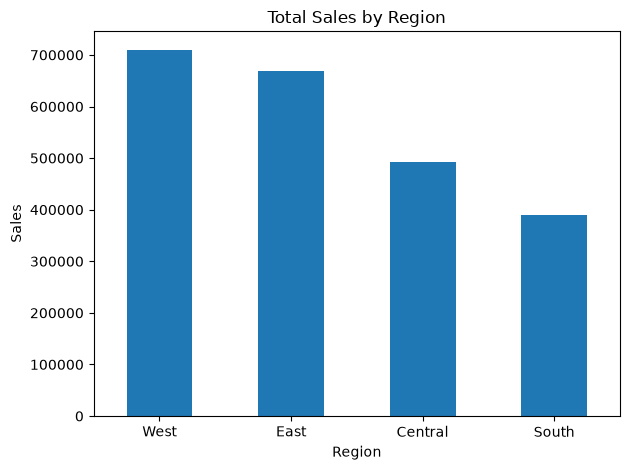

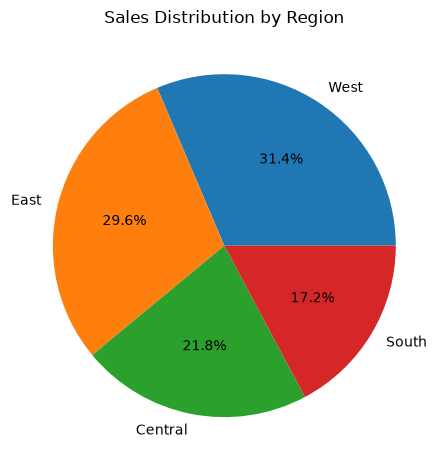

In [5]:
region_sales.plot(kind="bar", title="Total Sales by Region", ylabel="Sales", xlabel="Region")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

region_sales.plot(kind="pie", autopct="%1.1f%%", title="Sales Distribution by Region")
plt.ylabel("")
plt.tight_layout()
plt.show()

## Task 6: Identify the top-performing region

In [6]:
top_region = region_sales.idxmax()
top_sales = region_sales.max()

print("Top-performing region:", top_region)
print("Total sales:", round(top_sales, 2))

Top-performing region: West
Total sales: 710219.68


## Task 7: Calculate sales by region and product category

In [7]:
region_category_sales = df.groupby(["Region", "Category"])["Sales"].sum().unstack()
print(region_category_sales)

Category    Furniture  Office Supplies  Technology
Region                                            
Central   160317.4622       163590.243  168739.208
East      206461.3880       199940.811  263116.527
South     116531.4800       124424.771  148195.208
West      245348.2455       217466.509  247404.930


## Task 8: Compare sales across regions and product categories

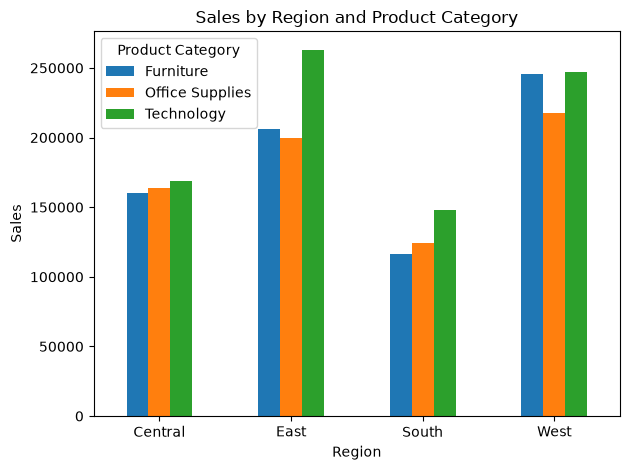

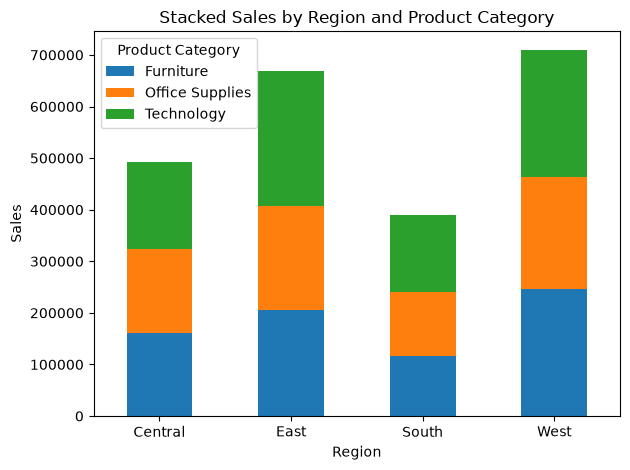

In [8]:
region_category_sales.plot(kind="bar", title="Sales by Region and Product Category")
plt.xlabel("Region")
plt.ylabel("Sales")
plt.xticks(rotation=0)
plt.legend(title="Product Category")
plt.tight_layout()
plt.show()

region_category_sales.plot(kind="bar", stacked=True, title="Stacked Sales by Region and Product Category")
plt.xlabel("Region")
plt.ylabel("Sales")
plt.xticks(rotation=0)
plt.legend(title="Product Category")
plt.tight_layout()
plt.show()

## Conclusion

Sales were grouped by region to calculate total sales and identify the top-performing region. Sales were also grouped by region and product category and visualized using grouped and stacked bar charts.

**Dataset limitation:** This dataset does not include a quantity-sold field, so quantity-based analysis is not performed.